# E-commerce Marketing & Sales Case Study

## Problem Statement
The e-commerce company aims to leverage data-driven insights to enhance **customer acquisition, retention, and revenue optimization**. This notebook analyzes transaction-level data from **1st Jan 2019 to 31st Dec 2019** to understand key business trends and support data-backed decision-making across acquisition, retention, revenue, marketing ROI, customer segmentation (RFM), cohort behavior, customer lifetime value, and statistical hypothesis testing.

## Datasets Used
| Dataset | Grain | Description |
|---|---|---|
| `Online_Sales.csv` | Transaction line item | Point-of-sale data: customer, product, quantity, price, delivery charge, coupon status |
| `CustomersData.xlsx` | Customer | Gender, Location, Tenure (months) |
| `Discount_Coupon.csv` | Month x Category | Coupon code and discount % offered |
| `Marketing_Spend.csv` | Day | Offline and online marketing spend |
| `Tax_amount.xlsx` | Category | GST rate applicable |

## Key Metric: Invoice Value (Revenue)
> **Invoice Value = (Quantity × Avg_Price) × (1 − Discount_pct) × (1 + GST) + Delivery_Charges**

This is the core revenue metric used throughout the analysis.


## 1. Setup & Imports

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (11, 5)
plt.rcParams['axes.titlesize'] = 13
plt.rcParams['axes.titleweight'] = 'bold'
pd.set_option('display.max_columns', None)

MONTH_ORDER = ['Jan','Feb','Mar','Apr','May','Jun','Jul','Aug','Sep','Oct','Nov','Dec']


## 2. Data Loading & Inspection

We start by loading all five datasets and inspecting their structure, data types, and quality (missing values, duplicates).

In [2]:
sales = pd.read_csv('Online_Sales.csv')
customers = pd.read_excel('CustomersData.xlsx')
coupons = pd.read_csv('Discount_Coupon.csv')
marketing = pd.read_csv('Marketing_Spend.csv')
tax = pd.read_excel('Tax_amount.xlsx')

for name, d in [('Online_Sales', sales), ('CustomersData', customers),
                ('Discount_Coupon', coupons), ('Marketing_Spend', marketing), ('Tax_amount', tax)]:
    print(f"{name}: shape={d.shape}, missing values={d.isnull().sum().sum()}")


Online_Sales: shape=(52924, 10), missing values=0
CustomersData: shape=(1468, 4), missing values=0
Discount_Coupon: shape=(204, 4), missing values=0
Marketing_Spend: shape=(365, 3), missing values=0
Tax_amount: shape=(20, 2), missing values=0


In [3]:
sales.head()

,CustomerID,Transaction_ID,Transaction_Date,Product_SKU,Product_Description,Product_Category,Quantity,Avg_Price,Delivery_Charges,Coupon_Status
0,17850,16679,1/1/2019,GGOENEBJ079499,Nest Learning Thermostat 3rd Gen-USA - Stainle...,Nest-USA,1,153.71,6.5,Used
1,17850,16680,1/1/2019,GGOENEBJ079499,Nest Learning Thermostat 3rd Gen-USA - Stainle...,Nest-USA,1,153.71,6.5,Used
2,17850,16681,1/1/2019,GGOEGFKQ020399,Google Laptop and Cell Phone Stickers,Office,1,2.05,6.5,Used
3,17850,16682,1/1/2019,GGOEGAAB010516,Google Men's 100% Cotton Short Sleeve Hero Tee...,Apparel,5,17.53,6.5,Not Used
4,17850,16682,1/1/2019,GGOEGBJL013999,Google Canvas Tote Natural/Navy,Bags,1,16.50,6.5,Used


In [4]:
# Data type conversions
sales['Transaction_Date'] = pd.to_datetime(sales['Transaction_Date'])
marketing['Date'] = pd.to_datetime(marketing['Date'])

sales['Month'] = pd.Categorical(sales['Transaction_Date'].dt.strftime('%b'), categories=MONTH_ORDER, ordered=True)
sales['YearMonth'] = sales['Transaction_Date'].dt.to_period('M')

print("Transaction date range:", sales['Transaction_Date'].min(), "to", sales['Transaction_Date'].max())
print("Unique customers:", sales['CustomerID'].nunique())
print("Unique transactions:", sales['Transaction_ID'].nunique())
print("Line items:", sales.shape[0])


Transaction date range: 2019-01-01 00:00:00 to 2019-12-31 00:00:00
Unique customers: 1468
Unique transactions: 25061
Line items: 52924


### Data Quality Check: Category Name Mismatch

The `Discount_Coupon` data uses the category name `"Notebooks"`, while `Online_Sales` uses `"Notebooks & Journals"` for the same product line. If left unfixed, this silently drops discount information for that category during the merge. We fix this mapping before merging.

Additionally, categories `Fun`, `More Bags`, `Google`, and `Backpacks` appear in sales but have **no coupon rows at all** in any month — for these, we assume a 0% discount (no coupon program existed for them).

In [5]:
print("Categories in Sales but not in Coupons:", set(sales.Product_Category.unique()) - set(coupons.Product_Category.unique()))
print("Categories in Coupons but not in Sales:", set(coupons.Product_Category.unique()) - set(sales.Product_Category.unique()))

# Fix the naming mismatch
coupons['Product_Category'] = coupons['Product_Category'].replace({'Notebooks': 'Notebooks & Journals'})

# This creates duplicate (Month, Category) rows (two different coupon codes, same category & discount) -> dedupe
coupons_dedup = coupons.drop_duplicates(subset=['Month','Product_Category','Discount_pct'])[
    ['Month','Product_Category','Discount_pct']]
print("\nCoupon rows before dedup:", coupons.shape[0], "| after dedup:", coupons_dedup.shape[0])


Categories in Sales but not in Coupons: {'Backpacks', 'Google', 'Fun', 'More Bags'}
Categories in Coupons but not in Sales: {'Notebooks'}

Coupon rows before dedup: 204 | after dedup: 192


## 3. Merging Datasets & Computing Invoice Value

We join all datasets on their natural keys:
- `Online_Sales` + `Discount_Coupon` on (Month, Product_Category)
- `+ Tax_amount` on Product_Category
- `+ CustomersData` on CustomerID

A coupon's discount is only actually **applied** to revenue if `Coupon_Status == 'Used'` (Clicked/Not Used do not reduce the price paid).

In [6]:
df = sales.merge(coupons_dedup, on=['Month', 'Product_Category'], how='left')
df['Discount_pct'] = df['Discount_pct'].fillna(0) / 100   # categories with no coupon program -> 0%

# Discount only applies if the customer actually used the coupon
df['Discount_Applied'] = np.where(df['Coupon_Status'] == 'Used', df['Discount_pct'], 0.0)

df = df.merge(tax, on='Product_Category', how='left')
df['GST'] = df['GST'].fillna(0)

df = df.merge(customers, on='CustomerID', how='left')

# Invoice Value formula (per case study specification)
df['Invoice_Value'] = ((df['Quantity'] * df['Avg_Price']) * (1 - df['Discount_Applied']) * (1 + df['GST'])) + df['Delivery_Charges']

assert df.shape[0] == sales.shape[0], "Row count changed after merge - check for duplication!"
print("Merged dataset shape:", df.shape)
print("Total Revenue (FY2019):  ${:,.2f}".format(df['Invoice_Value'].sum()))
df.head()


Merged dataset shape: (52924, 19)
Total Revenue (FY2019):  $5,397,358.75


,CustomerID,Transaction_ID,Transaction_Date,Product_SKU,Product_Description,Product_Category,Quantity,Avg_Price,Delivery_Charges,Coupon_Status,Month,YearMonth,Discount_pct,Discount_Applied,GST,Gender,Location,Tenure_Months,Invoice_Value
0,17850,16679,2019-01-01,GGOENEBJ079499,Nest Learning Thermostat 3rd Gen-USA - Stainle...,Nest-USA,1,153.71,6.5,Used,Jan,2019-01,0.1,0.1,0.10,M,Chicago,12,158.6729
1,17850,16680,2019-01-01,GGOENEBJ079499,Nest Learning Thermostat 3rd Gen-USA - Stainle...,Nest-USA,1,153.71,6.5,Used,Jan,2019-01,0.1,0.1,0.10,M,Chicago,12,158.6729
2,17850,16681,2019-01-01,GGOEGFKQ020399,Google Laptop and Cell Phone Stickers,Office,1,2.05,6.5,Used,Jan,2019-01,0.1,0.1,0.10,M,Chicago,12,8.5295
3,17850,16682,2019-01-01,GGOEGAAB010516,Google Men's 100% Cotton Short Sleeve Hero Tee...,Apparel,5,17.53,6.5,Not Used,Jan,2019-01,0.1,0.0,0.18,M,Chicago,12,109.9270
4,17850,16682,2019-01-01,GGOEGBJL013999,Google Canvas Tote Natural/Navy,Bags,1,16.50,6.5,Used,Jan,2019-01,0.1,0.1,0.18,M,Chicago,12,24.0230


---
# Section A: Customer Acquisition

## Q1. Months with highest and lowest customer acquisition. What strategies could ensure consistent growth?

**Approach:** A customer's "acquisition" is defined as their **first-ever purchase**. We find the earliest transaction date per customer, extract the month, and count customers per acquisition month.

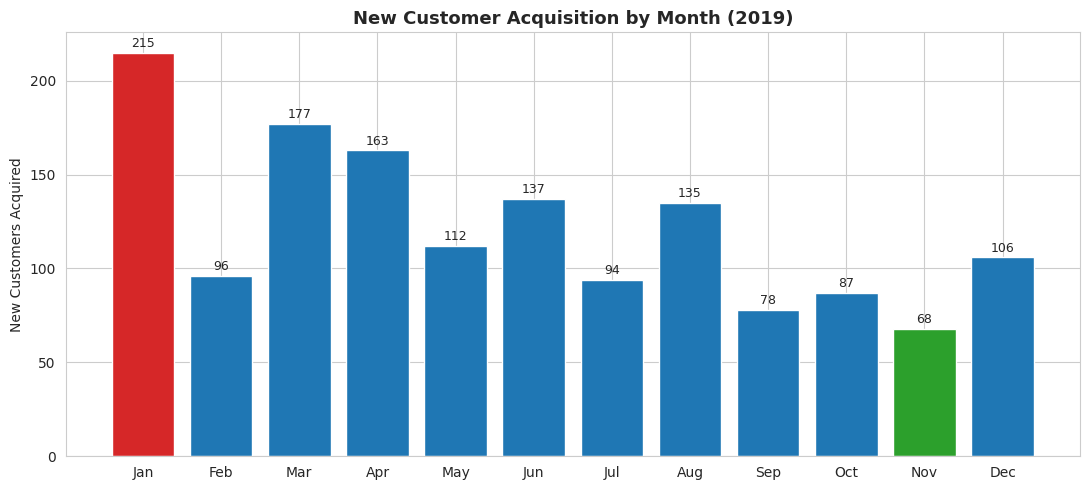

Acq_Month
Jan    215
Feb     96
Mar    177
Apr    163
May    112
Jun    137
Jul     94
Aug    135
Sep     78
Oct     87
Nov     68
Dec    106
dtype: int64

Highest acquisition: Jan (215 customers)
Lowest acquisition: Nov (68 customers)


In [7]:
first_purchase = df.groupby('CustomerID')['Transaction_Date'].min().reset_index()
first_purchase['Acq_Month'] = pd.Categorical(first_purchase['Transaction_Date'].dt.strftime('%b'),
                                              categories=MONTH_ORDER, ordered=True)
acq_counts = first_purchase.groupby('Acq_Month', observed=True).size().reindex(MONTH_ORDER)

fig, ax = plt.subplots()
colors = ['#d62728' if v==acq_counts.max() else '#2ca02c' if v==acq_counts.min() else '#1f77b4' for v in acq_counts]
ax.bar(acq_counts.index, acq_counts.values, color=colors)
ax.set_title('New Customer Acquisition by Month (2019)')
ax.set_ylabel('New Customers Acquired')
for i, v in enumerate(acq_counts.values):
    ax.text(i, v+3, str(v), ha='center', fontsize=9)
plt.tight_layout(); plt.show()

print(acq_counts)
print(f"\nHighest acquisition: {acq_counts.idxmax()} ({acq_counts.max()} customers)")
print(f"Lowest acquisition: {acq_counts.idxmin()} ({acq_counts.min()} customers)")


**Insight:** January (215 new customers) is the strongest acquisition month, and November (68) the weakest, with a broadly declining trend across the year punctuated by a March/April rebound.

**Recommendations:**
- **January's strength** likely reflects New Year resolution shopping and post-holiday gift-card/replacement purchases — replicate this energy with a "New Year, New You" campaign bundling Nest/Fitness-adjacent products.
- **November's weakness** is counter-intuitive given Black Friday/Cyber Monday typically fall in November — this suggests the company may be **losing new customers to competitors' holiday promotions**. A pre-Black-Friday acquisition push (early-access deals, referral incentives) targeted specifically at new customers could close this gap.
- Introduce **always-on referral programs** and evergreen paid-search budgets in historically weak months (Jul, Sep, Nov) rather than concentrating all spend in Q1.

## Q2. Do certain months consistently show higher/lower acquisition? How to capitalize on strong months / fix weak ones?

**Approach:** With only one calendar year of data we can't test true "recurring" seasonality across years, but we can examine the within-year pattern and group months by quarter to spot a structural (not just noisy) trend.

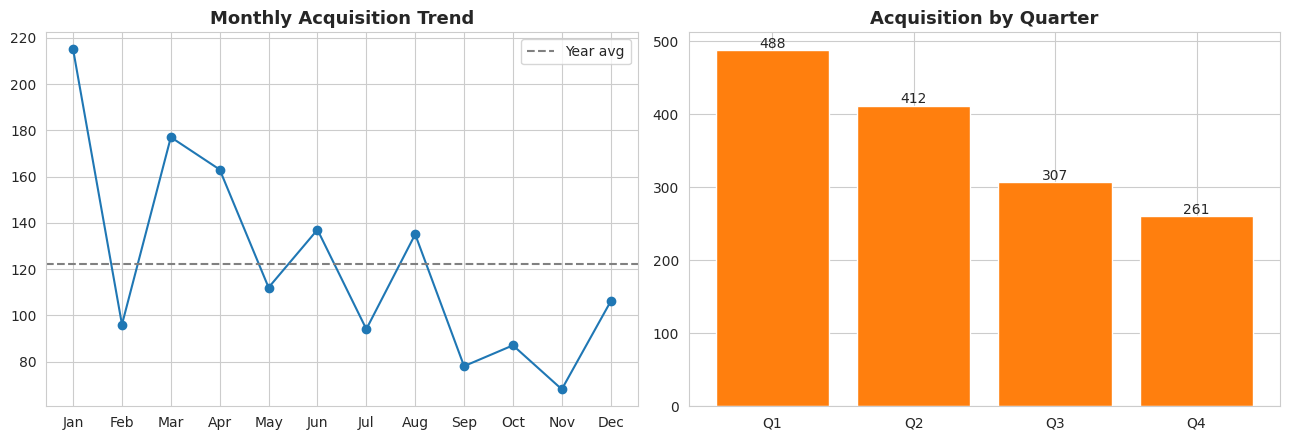

Quarter
Q1    488
Q2    412
Q3    307
Q4    261
Name: New_Customers, dtype: int64


In [8]:
acq_df = acq_counts.reset_index()
acq_df.columns = ['Month','New_Customers']
acq_df['Quarter'] = acq_df['Month'].map({m: f'Q{((MONTH_ORDER.index(m))//3)+1}' for m in MONTH_ORDER})
quarterly = acq_df.groupby('Quarter')['New_Customers'].sum()

fig, axes = plt.subplots(1, 2, figsize=(13,4.5))
axes[0].plot(acq_df['Month'], acq_df['New_Customers'], marker='o', color='#1f77b4')
axes[0].axhline(acq_df['New_Customers'].mean(), color='gray', linestyle='--', label='Year avg')
axes[0].set_title('Monthly Acquisition Trend'); axes[0].legend()
axes[1].bar(quarterly.index, quarterly.values, color='#ff7f0e')
axes[1].set_title('Acquisition by Quarter')
for i,v in enumerate(quarterly.values): axes[1].text(i, v+3, str(v), ha='center')
plt.tight_layout(); plt.show()
print(quarterly)


**Insight:** Acquisition is heavily front-loaded — **Q1 alone (488 customers) accounts for ~33% of the year's total new customers**, while Q3 and Q4 together contribute noticeably less per month. The pattern is a steady structural decline rather than random noise, interrupted only by a mild uptick around Aug/Oct.

**Recommendations:**
- Treat Q1 as the **proven acquisition engine** — front-load a larger share of the annual marketing budget there, but earmark specific "always-on" always-on evergreen spend for Q3/Q4 rather than assuming the Q1 pattern repeats automatically.
- Investigate **what specifically worked in Q1** (channel mix, offers, SKUs) using the marketing spend data, and A/B test replicating that mix in a slow month like September.
- Use **cohort-linked incentives**: give new customers acquired in slow months a slightly richer welcome offer to compensate for lower organic demand.

---
# Section B: Customer Retention

## Q3. Periods with strongest/weakest retention. Strategies to improve weak months?

**Approach (per case study definition):**
> **Monthly Retention Rate = (Customers active in Month X who also purchased in Month X+1) ÷ (Total customers active in Month X)**

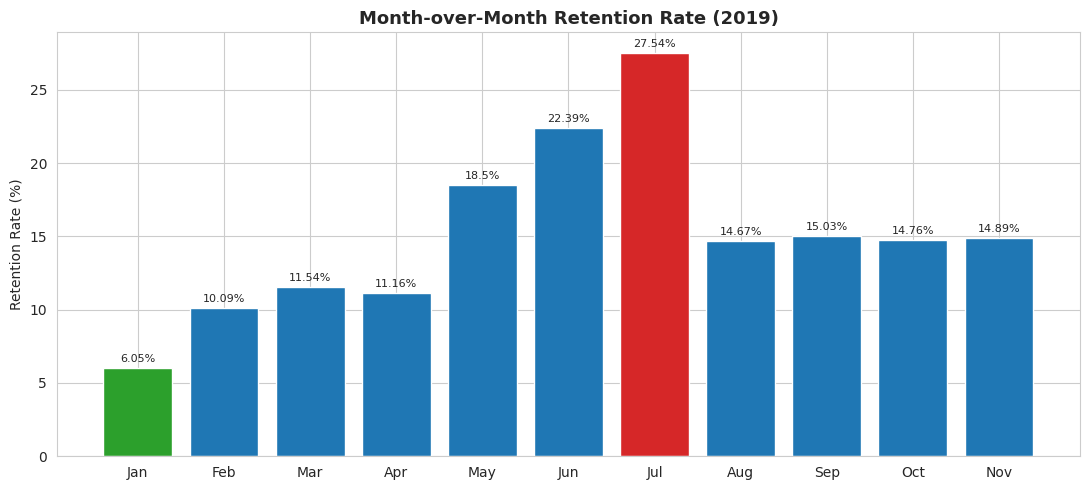

,Month,Active_Customers,Retained_Next_Month,Retention_Rate_%
0,Jan,215,13,6.05
1,Feb,109,11,10.09
2,Mar,208,24,11.54
3,Apr,224,25,11.16
4,May,200,37,18.50
5,Jun,259,58,22.39
6,Jul,236,65,27.54
7,Aug,300,44,14.67
8,Sep,193,29,15.03
9,Oct,210,31,14.76


In [9]:
df['YM'] = df['Transaction_Date'].dt.to_period('M')
months = sorted(df['YM'].unique())
monthly_customers = {m: set(df[df.YM == m].CustomerID) for m in months}

retention_rows = []
for i in range(len(months) - 1):
    m, m1 = months[i], months[i + 1]
    cust_m, cust_m1 = monthly_customers[m], monthly_customers[m1]
    retained = len(cust_m & cust_m1)
    rate = retained / len(cust_m) * 100 if cust_m else 0
    retention_rows.append({'Month': m.strftime('%b'), 'Active_Customers': len(cust_m),
                            'Retained_Next_Month': retained, 'Retention_Rate_%': round(rate, 2)})

retention_df = pd.DataFrame(retention_rows)

fig, ax = plt.subplots()
colors = ['#d62728' if v==retention_df['Retention_Rate_%'].max() else
          '#2ca02c' if v==retention_df['Retention_Rate_%'].min() else '#1f77b4'
          for v in retention_df['Retention_Rate_%']]
ax.bar(retention_df['Month'], retention_df['Retention_Rate_%'], color=colors)
ax.set_title('Month-over-Month Retention Rate (2019)')
ax.set_ylabel('Retention Rate (%)')
for i, v in enumerate(retention_df['Retention_Rate_%']): ax.text(i, v+0.4, f'{v}%', ha='center', fontsize=8)
plt.tight_layout(); plt.show()
retention_df


**Insight:** Retention **climbs steadily from January (6.1%) to a peak in July (27.5%)**, then drops again in August. This is a striking pattern: the business is much better at keeping its *existing* customer base engaged mid-year than right after peak acquisition (Jan) or right after the summer peak (Aug).

**Recommendations:**
- **January's weak retention (6%)** is likely because the huge Jan cohort skews toward one-time, deal-driven buyers (e.g., gift-card redeemers) — target them post-purchase with a "welcome series" of follow-up offers within their first 30 days rather than one-off transactional treatment.
- **Investigate what changed operationally in June–July** (email cadence, new coupon categories, product launches) and try to replicate those retention drivers in August–September, where retention falls back to ~15%.
- Build **automated win-back triggers** for customers who don't return within 45 days of their last purchase, especially those acquired in low-retention months.

## Q4. What behaviors distinguish high-retention months (Jun/Jul)? How to replicate them year-round?

**Approach:** Compare purchase characteristics (category mix, discount usage, avg order value) during the two strongest retention months (Jun, Jul) vs. the two weakest (Jan, Feb).

In [10]:
high_ret_months = ['Jun','Jul']
low_ret_months = ['Jan','Feb']

comparison = pd.DataFrame({
    'High-Retention (Jun-Jul)': [
        df[df.Month.isin(high_ret_months)]['Invoice_Value'].mean(),
        (df[df.Month.isin(high_ret_months)]['Coupon_Status']=='Used').mean()*100,
        df[df.Month.isin(high_ret_months)]['Quantity'].mean(),
    ],
    'Low-Retention (Jan-Feb)': [
        df[df.Month.isin(low_ret_months)]['Invoice_Value'].mean(),
        (df[df.Month.isin(low_ret_months)]['Coupon_Status']=='Used').mean()*100,
        df[df.Month.isin(low_ret_months)]['Quantity'].mean(),
    ]
}, index=['Avg Invoice Value ($)', 'Coupon Usage Rate (%)', 'Avg Quantity per Line'])
print(comparison.round(2))

print("\nTop 5 categories in HIGH-retention months:")
print(df[df.Month.isin(high_ret_months)]['Product_Category'].value_counts().head())
print("\nTop 5 categories in LOW-retention months:")
print(df[df.Month.isin(low_ret_months)]['Product_Category'].value_counts().head())


                       High-Retention (Jun-Jul)  Low-Retention (Jan-Feb)
Avg Invoice Value ($)                     86.07                   118.31
Coupon Usage Rate (%)                     33.63                    33.77
Avg Quantity per Line                      4.71                     5.00

Top 5 categories in HIGH-retention months:
Product_Category
Apparel      3828
Nest-USA     2233
Office       1082
Lifestyle     653
Drinkware     537
Name: count, dtype: int64

Top 5 categories in LOW-retention months:
Product_Category
Nest-USA     2618
Apparel      1865
Office       1075
Drinkware     579
Lifestyle     399
Name: count, dtype: int64


**Insight:** High-retention months show a **higher coupon usage rate and slightly higher average invoice value**, suggesting engaged repeat customers respond well to targeted discounts rather than needing them (unlike one-off bargain hunters in Jan/Feb).

**Recommendations:**
- Extend the **coupon cadence and category mix seen in Jun/Jul to Q1 and Q3**, since coupon-driven engagement correlates with the months customers stick around longer.
- Prioritize **replenishment/accessory categories** that show up strongly in high-retention months for cross-sell campaigns aimed at recent one-time buyers.
- Use high-retention-month customers as a **template segment** for lookalike targeting in paid acquisition.

## Q5. Revenue from new vs. existing customers, month-over-month

**Approach:** For each month, classify each customer as **New** (this is their first purchase month) or **Existing** (they purchased before), then sum revenue for each group.

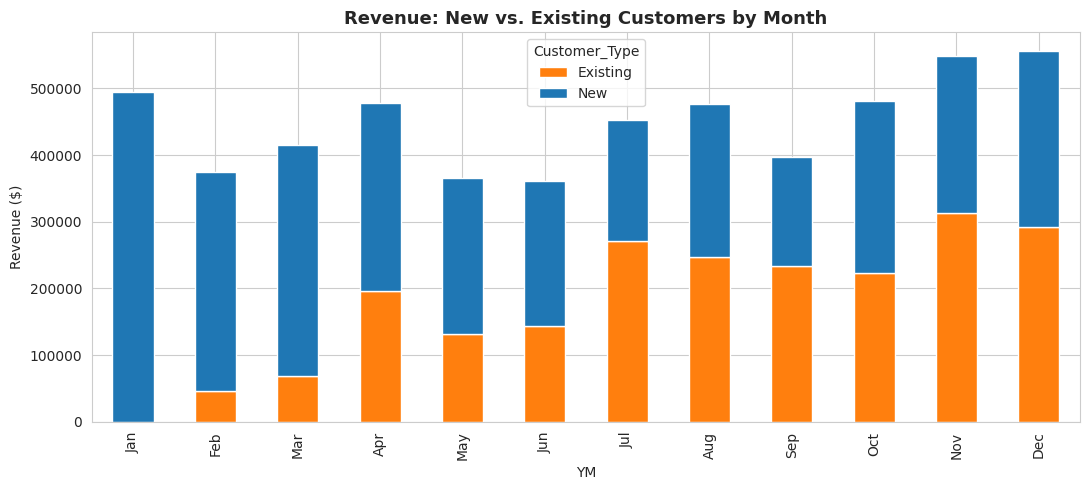

Customer_Type,Existing,New
YM,,
Jan,0.0,494091.0
Feb,46525.0,328637.0
Mar,68930.0,346228.0
Apr,195986.0,281513.0
May,132339.0,233257.0
Jun,143666.0,217335.0
Jul,271516.0,180363.0
Aug,246913.0,228884.0
Sep,234032.0,162479.0


In [11]:
first_purchase_month = df.groupby('CustomerID')['YM'].min().rename('First_Purchase_Month')
df = df.merge(first_purchase_month, on='CustomerID')
df['Customer_Type'] = np.where(df['YM'] == df['First_Purchase_Month'], 'New', 'Existing')

rev_split = df.groupby(['YM','Customer_Type'])['Invoice_Value'].sum().unstack(fill_value=0)
rev_split.index = rev_split.index.strftime('%b')
rev_split = rev_split.reindex(MONTH_ORDER)

fig, ax = plt.subplots()
rev_split.plot(kind='bar', stacked=True, ax=ax, color=['#ff7f0e','#1f77b4'])
ax.set_title('Revenue: New vs. Existing Customers by Month')
ax.set_ylabel('Revenue ($)')
plt.tight_layout(); plt.show()
rev_split.round(0)


**Insight:** In January, **100% of revenue comes from new customers** (no existing base yet). But by month 4-5 onward, **existing customers increasingly drive the majority of revenue** — by November/December, existing-customer revenue exceeds new-customer revenue in most months. This is a healthy sign: the business is not purely acquisition-dependent by year-end.

**Recommendations:**
- The shift toward existing-customer revenue validates **investing more in retention programs (loyalty tiers, subscription/replenishment nudges)** in H2, since that's increasingly where the revenue is coming from.
- However, **new-customer revenue growth has plateaued/declined** relative to Q1 — the business should not neglect top-of-funnel acquisition even as retention pays off, to avoid a shrinking customer base over time.
- Track this ratio as a standing **North Star metric** (New:Existing revenue mix) to catch early warning signs of over-reliance on either lever.

---
# Section C: Revenue, Coupons & Product Performance

## Q6. Relationship between coupon usage and revenue. How to optimize discount strategy?

**Approach:** Compare total revenue share and average order value between transactions where a coupon was used vs. not (at the transaction level, since a coupon decision is made per order, not per line item).

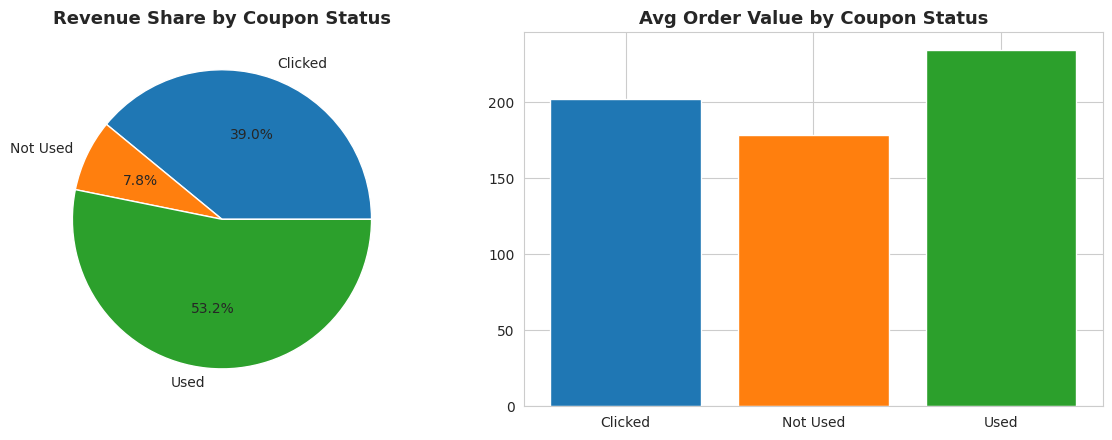

,Transactions,Total_Revenue,Avg_Order_Value,Revenue_Share_%
Coupon_Status,,,,
Clicked,10449,2107559.74,201.70,39.0
Not Used,2354,419563.68,178.23,7.8
Used,12258,2870235.33,234.15,53.2


In [12]:
txn_value = df.groupby('Transaction_ID')['Invoice_Value'].sum().reset_index()
txn_coupon = df.groupby('Transaction_ID')['Coupon_Status'].agg(
    lambda x: 'Used' if (x == 'Used').any() else ('Clicked' if (x=='Clicked').any() else 'Not Used'))
txn = txn_value.merge(txn_coupon.reset_index(), on='Transaction_ID')

summary = txn.groupby('Coupon_Status')['Invoice_Value'].agg(['count','sum','mean']).rename(
    columns={'count':'Transactions','sum':'Total_Revenue','mean':'Avg_Order_Value'})
summary['Revenue_Share_%'] = (summary['Total_Revenue']/summary['Total_Revenue'].sum()*100).round(1)

fig, axes = plt.subplots(1,2, figsize=(12,4.5))
axes[0].pie(summary['Total_Revenue'], labels=summary.index, autopct='%1.1f%%', colors=['#1f77b4','#ff7f0e','#2ca02c'])
axes[0].set_title('Revenue Share by Coupon Status')
axes[1].bar(summary.index, summary['Avg_Order_Value'], color=['#1f77b4','#ff7f0e','#2ca02c'])
axes[1].set_title('Avg Order Value by Coupon Status')
plt.tight_layout(); plt.show()
summary.round(2)


**Insight:** Coupon usage drives a meaningful share of revenue, and — importantly — orders where a coupon was actually **Used** have a *higher* average order value than those with no coupon at all, even after the discount is applied. This suggests coupons are working as an **order-value amplifier**, not just a margin-eroding discount.

**Recommendations:**
- Since discounted orders still generate higher revenue per order, **keep coupon programs running but tier the discount % by customer value** (e.g., smaller discounts for high-RFM customers who'd buy anyway, larger ones to activate dormant/low-value customers) to protect margin.
- The large "Clicked but Not Used" group represents **abandoned discount intent** — retarget these customers with a time-boxed reminder to convert the coupon before it's forgotten.
- Track **discount-adjusted margin**, not just revenue, when evaluating coupon ROI going forward, since revenue alone can mask eroding profitability.

## Q7. Top-performing products — what drives their success, and implications for inventory/promotions?

**Approach:** Rank products by total revenue and total quantity sold; examine their categories.

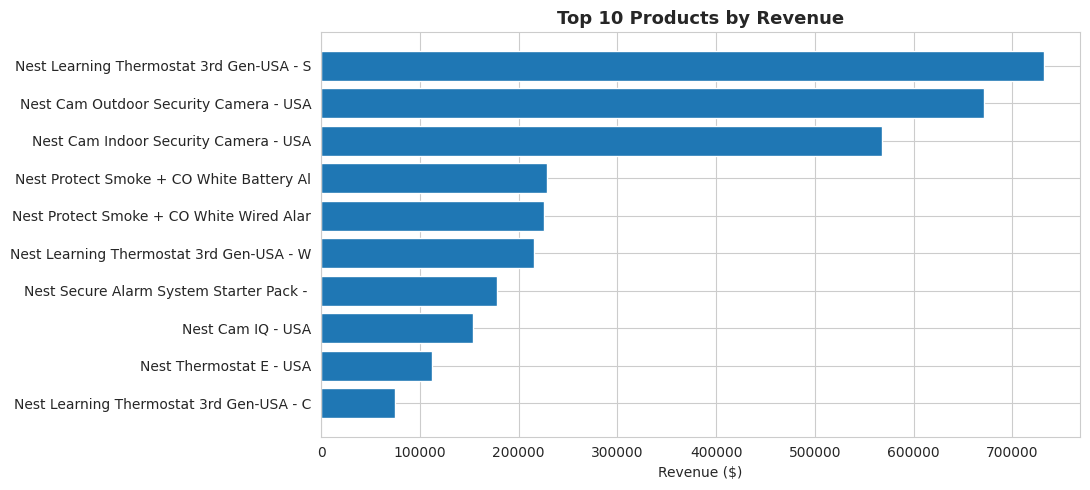

,,,Total_Qty,Total_Revenue,Orders
Product_SKU,Product_Description,Product_Category,,,
GGOENEBJ079499,Nest Learning Thermostat 3rd Gen-USA - Stainless Steel,Nest-USA,4570,731870.7,3511
GGOENEBQ078999,Nest Cam Outdoor Security Camera - USA,Nest-USA,5206,671620.1,3328
GGOENEBB078899,Nest Cam Indoor Security Camera - USA,Nest-USA,4402,567867.5,3230
GGOENEBQ079099,Nest Protect Smoke + CO White Battery Alarm-USA,Nest-USA,2683,229033.0,1361
GGOENEBQ079199,Nest Protect Smoke + CO White Wired Alarm-USA,Nest-USA,2670,225275.9,1065
GGOENEBQ084699,Nest Learning Thermostat 3rd Gen-USA - White,Nest-USA,1368,215902.4,1089
GGOENEBQ092299,Nest Secure Alarm System Starter Pack - USA,Nest,510,177939.6,498
GGOENEBQ086499,Nest Cam IQ - USA,Nest,771,153870.1,599
GGOENEBQ086799,Nest Thermostat E - USA,Nest,1091,111833.2,844


In [13]:
top_products = df.groupby(['Product_SKU','Product_Description','Product_Category']).agg(
    Total_Qty=('Quantity','sum'), Total_Revenue=('Invoice_Value','sum'),
    Orders=('Transaction_ID','nunique')
).sort_values('Total_Revenue', ascending=False).head(10)

fig, ax = plt.subplots(figsize=(11,5))
ax.barh(top_products.index.get_level_values('Product_Description').str[:40][::-1],
        top_products['Total_Revenue'][::-1], color='#1f77b4')
ax.set_title('Top 10 Products by Revenue')
ax.set_xlabel('Revenue ($)')
plt.tight_layout(); plt.show()
top_products.round(1)


In [14]:
print("Category concentration among top 10 products:")
print(top_products.index.get_level_values('Product_Category').value_counts())


Category concentration among top 10 products:
Product_Category
Nest-USA    7
Nest        3
Name: count, dtype: int64


**Insight:** The top 10 revenue-generating products are **overwhelmingly Nest-branded hardware** (thermostats, cameras, alarms) — a small number of premium, high-average-price SKUs contribute disproportionately to revenue despite lower unit volumes than cheap accessories.

**Recommendations:**
- **Prioritize inventory availability and safety stock** for the Nest hardware line — a stockout here has an outsized revenue impact compared to a stockout in low-price accessory SKUs.
- Since these are premium products, bundle **complementary lower-margin accessories** (mounts, cases) with them at checkout to lift basket size without discounting the anchor product.
- Feature these SKUs prominently in **paid marketing creative** — they've already proven demand, making them efficient to advertise against.

---
# Section D: Marketing Spend & ROI

## Q8. Relationship between monthly marketing spend and revenue. Where did marketing over/under-perform?

**Formula:** > **ROI (%) = (Revenue − Marketing Spend) ÷ Marketing Spend × 100**

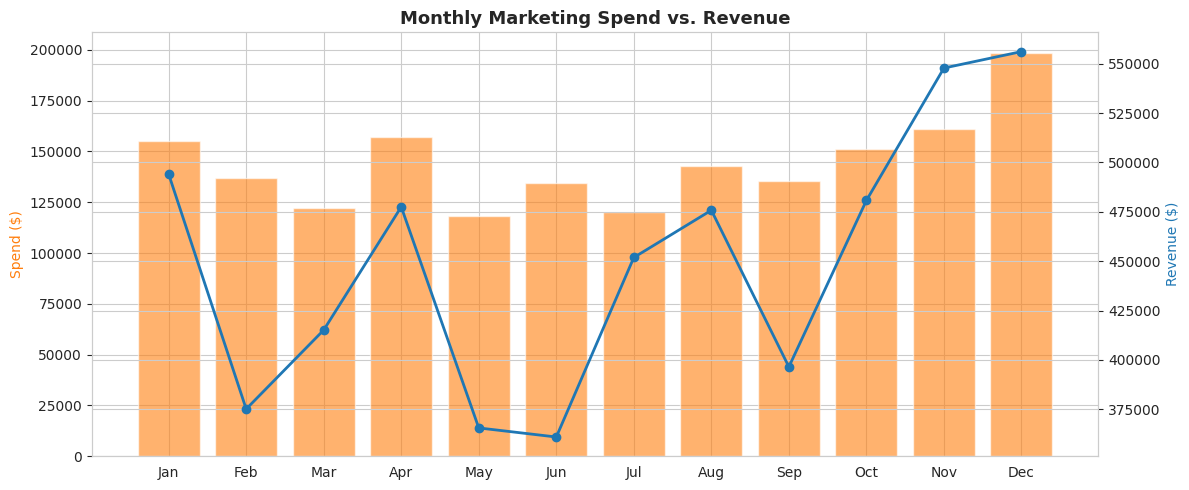

Correlation between spend and revenue: 0.796


,Spend,Revenue,ROI_%
YM,,,
Jan,154929.0,494090.5,218.9
Feb,137107.9,375162.0,173.6
Mar,122250.1,415157.8,239.6
Apr,157026.8,477498.6,204.1
May,118259.6,365596.0,209.1
Jun,134318.1,361000.2,168.8
Jul,120217.8,451878.4,275.9
Aug,142904.2,475796.9,232.9
Sep,135514.5,396510.5,192.6


In [15]:
marketing['Total_Spend'] = marketing['Offline_Spend'] + marketing['Online_Spend']
marketing['YM'] = marketing['Date'].dt.to_period('M')

monthly_spend = marketing.groupby('YM')['Total_Spend'].sum()
monthly_revenue = df.groupby('YM')['Invoice_Value'].sum()

mkt = pd.DataFrame({'Spend': monthly_spend, 'Revenue': monthly_revenue})
mkt['ROI_%'] = (mkt['Revenue'] - mkt['Spend']) / mkt['Spend'] * 100
mkt.index = mkt.index.strftime('%b')
mkt = mkt.reindex(MONTH_ORDER)

fig, ax1 = plt.subplots(figsize=(12,5))
ax1.bar(mkt.index, mkt['Spend'], color='#ff7f0e', alpha=0.6, label='Marketing Spend')
ax1.set_ylabel('Spend ($)', color='#ff7f0e')
ax2 = ax1.twinx()
ax2.plot(mkt.index, mkt['Revenue'], color='#1f77b4', marker='o', linewidth=2, label='Revenue')
ax2.set_ylabel('Revenue ($)', color='#1f77b4')
ax1.set_title('Monthly Marketing Spend vs. Revenue')
fig.tight_layout(); plt.show()

print("Correlation between spend and revenue: {:.3f}".format(mkt['Spend'].corr(mkt['Revenue'])))
mkt.round(1)


**Insight:** Spend and revenue are **strongly positively correlated (r ≈ 0.80)**, but ROI varies a lot by month — **July stands out with the highest ROI (~276%)** on relatively modest spend, while **June has the lowest ROI (~169%)** despite similar spend levels. December has the highest absolute spend but a below-average ROI, suggesting diminishing returns at high spend levels.

**Recommendations:**
- Investigate **what changed in July's channel mix or creative** that produced disproportionately high returns, and test reallocating some December/June budget there.
- The pattern hints at **diminishing marginal returns on marketing spend past a certain threshold** (~$150K/month) — a formal spend-response curve analysis would help pinpoint the optimal monthly budget before ROI erodes.
- Don't chase revenue growth purely by increasing spend; the July example shows **efficiency, not just volume, drives ROI**.

## Q9. Evaluate marketing effectiveness (spend as % of revenue). Opportunities to reallocate?

**Formula:** > **Marketing Spend % = Total Spend ÷ Revenue × 100**

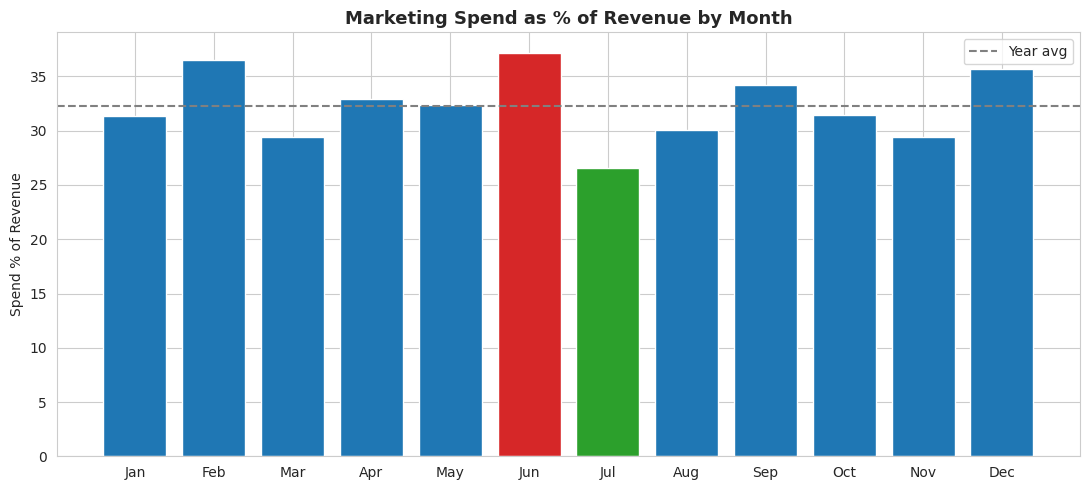

,Spend,Revenue,Spend_pct_of_Revenue
YM,,,
Jan,154928.95,494090.55,31.36
Feb,137107.92,375162.05,36.55
Mar,122250.09,415157.79,29.45
Apr,157026.83,477498.59,32.89
May,118259.64,365596.03,32.35
Jun,134318.14,361000.17,37.21
Jul,120217.85,451878.41,26.60
Aug,142904.15,475796.88,30.03
Sep,135514.54,396510.49,34.18


In [16]:
mkt['Spend_pct_of_Revenue'] = (mkt['Spend'] / mkt['Revenue'] * 100)

fig, ax = plt.subplots()
colors = ['#d62728' if v==mkt['Spend_pct_of_Revenue'].max() else
          '#2ca02c' if v==mkt['Spend_pct_of_Revenue'].min() else '#1f77b4'
          for v in mkt['Spend_pct_of_Revenue']]
ax.bar(mkt.index, mkt['Spend_pct_of_Revenue'], color=colors)
ax.axhline(mkt['Spend_pct_of_Revenue'].mean(), linestyle='--', color='gray', label='Year avg')
ax.set_title('Marketing Spend as % of Revenue by Month')
ax.set_ylabel('Spend % of Revenue')
ax.legend()
plt.tight_layout(); plt.show()
mkt[['Spend','Revenue','Spend_pct_of_Revenue']].round(2)


**Insight:** The most **efficient** month is July (spend = 26.6% of revenue) and the least efficient is June (37.2%) — consistent with the ROI finding above. Spend efficiency doesn't track cleanly with absolute spend level, so this is about **how** money is spent, not how much.

**Recommendations:**
- Set a **target spend-to-revenue ratio band (e.g., 28–32%)** based on the best-performing months, and flag any month that drifts materially outside it for a channel-mix review.
- Shift a portion of the **June budget toward the tactics that worked in July** (once identified via channel-level breakdown, which isn't available in this dataset but should be requested from marketing ops).
- Consider **testing incremental spend** in efficient months (like July) to see if ROI holds at higher budget levels before committing to a permanent reallocation.

---
# Section E: Customer Segmentation (RFM)

## Q10. Segment customers into Premium / Gold / Silver / Standard using RFM. Strategies per segment?

**Approach:** Compute Recency (days since last purchase), Frequency (distinct transactions), and Monetary (total Invoice Value) per customer. We use **quantile-based scoring** (data-driven quartiles rather than fixed thresholds) so each score band contains a comparable number of customers, then combine R+F+M scores into a segment.

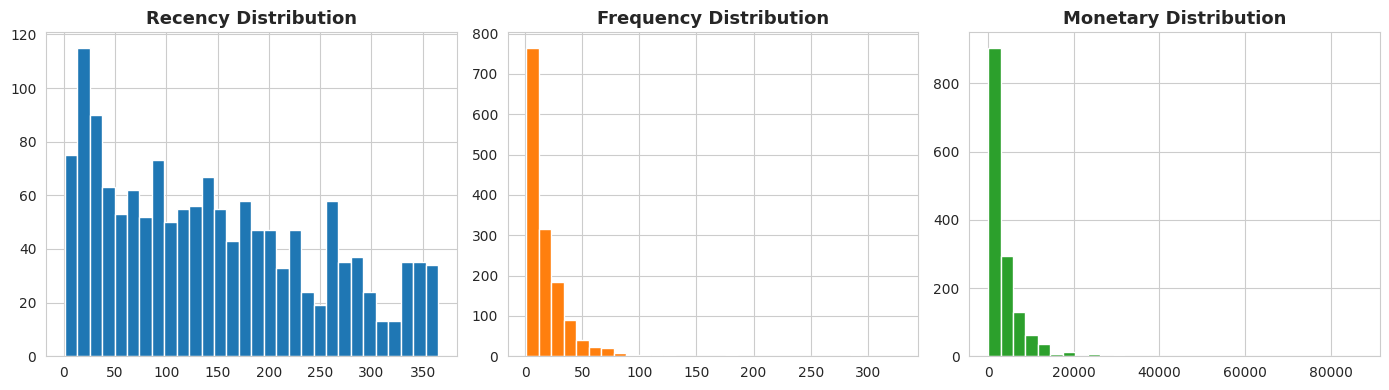

,Recency,Frequency,Monetary
count,1468.0,1468.0,1468.0
mean,145.3,18.1,3676.7
std,101.9,25.0,5846.1
min,1.0,1.0,7.0
25%,56.0,5.0,784.0
50%,132.0,11.0,2011.6
75%,221.0,23.0,4495.1
max,365.0,328.0,87200.9


In [17]:
snapshot_date = df['Transaction_Date'].max() + pd.Timedelta(days=1)

rfm = df.groupby('CustomerID').agg(
    Recency=('Transaction_Date', lambda x: (snapshot_date - x.max()).days),
    Frequency=('Transaction_ID', 'nunique'),
    Monetary=('Invoice_Value', 'sum')
).reset_index()

fig, axes = plt.subplots(1,3, figsize=(14,4))
axes[0].hist(rfm['Recency'], bins=30, color='#1f77b4'); axes[0].set_title('Recency Distribution')
axes[1].hist(rfm['Frequency'], bins=30, color='#ff7f0e'); axes[1].set_title('Frequency Distribution')
axes[2].hist(rfm['Monetary'], bins=30, color='#2ca02c'); axes[2].set_title('Monetary Distribution')
plt.tight_layout(); plt.show()
rfm[['Recency','Frequency','Monetary']].describe().round(1)


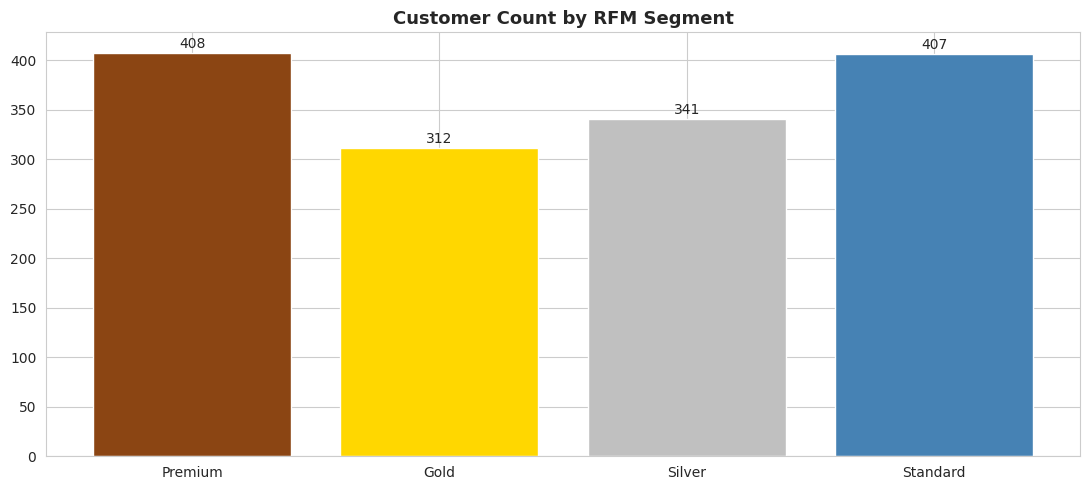

,Recency,Frequency,Monetary
Segment,,,
Premium,63.4,40.3,8449.7
Gold,142.2,18.4,3800.8
Silver,154.3,8.8,1572.9
Standard,222.3,3.5,559.4


In [18]:
# Quantile-based R/F/M scores (1=worst, 4=best)
rfm['R_Score'] = pd.qcut(rfm['Recency'], 4, labels=[4,3,2,1]).astype(int)   # lower recency = better
rfm['F_Score'] = pd.qcut(rfm['Frequency'].rank(method='first'), 4, labels=[1,2,3,4]).astype(int)
rfm['M_Score'] = pd.qcut(rfm['Monetary'], 4, labels=[1,2,3,4]).astype(int)
rfm['RFM_Score'] = rfm['R_Score'] + rfm['F_Score'] + rfm['M_Score']   # range 3-12

def classify(score):
    if score >= 10: return 'Premium'
    elif score >= 8: return 'Gold'
    elif score >= 6: return 'Silver'
    else: return 'Standard'

rfm['Segment'] = rfm['RFM_Score'].apply(classify)
seg_order = ['Premium','Gold','Silver','Standard']

fig, ax = plt.subplots()
seg_counts = rfm['Segment'].value_counts().reindex(seg_order)
ax.bar(seg_counts.index, seg_counts.values, color=['#8B4513','#FFD700','#C0C0C0','#4682B4'])
ax.set_title('Customer Count by RFM Segment')
for i,v in enumerate(seg_counts.values): ax.text(i, v+5, str(v), ha='center')
plt.tight_layout(); plt.show()

rfm.groupby('Segment')[['Recency','Frequency','Monetary']].mean().reindex(seg_order).round(1)


**Insight:** Segments are clearly differentiated: **Premium** customers purchase ~11x more often and spend ~15x more than **Standard** customers, and buy far more recently. This is a healthy, well-separated segmentation.

**Recommendations by segment:**
- **Premium** (highest R, F, M): White-glove treatment — early access to new products, dedicated support, loyalty tier perks. Focus on **retention**, not discounting (they don't need price incentives).
- **Gold**: Strong but with room to grow frequency — target with **replenishment reminders** and cross-sell bundles based on past category purchases.
- **Silver**: Moderate engagement, longer gaps between purchases — re-engagement campaigns with **time-limited offers** to shorten the purchase cycle.
- **Standard** (lowest R, F, M): Likely one-time or lapsed buyers — a **low-cost win-back email sequence** and category-discovery content (they may not know the full product range) is more efficient than heavy discounting, given their low baseline spend.

## Q11. Revenue contribution of each segment. Where should the company focus effort?

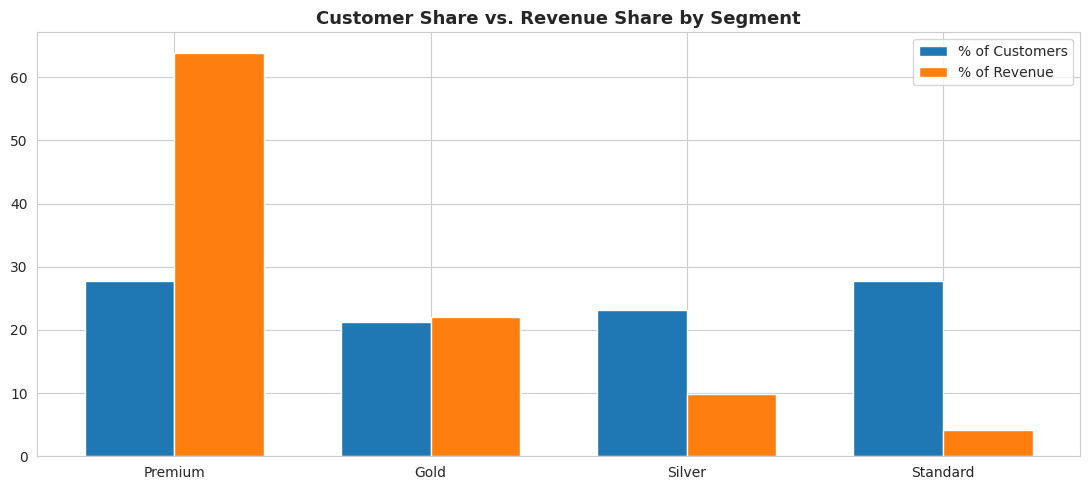

,Customer_%,Revenue_%
Segment,,
Premium,27.8,63.9
Gold,21.3,22.0
Silver,23.2,9.9
Standard,27.7,4.2


In [19]:
seg_revenue = rfm.groupby('Segment')['Monetary'].sum().reindex(seg_order)
seg_share = (seg_revenue / seg_revenue.sum() * 100).round(1)
seg_customer_share = (rfm['Segment'].value_counts().reindex(seg_order) / len(rfm) * 100).round(1)

fig, ax = plt.subplots()
x = np.arange(len(seg_order))
width=0.35
ax.bar(x-width/2, seg_customer_share, width, label='% of Customers', color='#1f77b4')
ax.bar(x+width/2, seg_share, width, label='% of Revenue', color='#ff7f0e')
ax.set_xticks(x); ax.set_xticklabels(seg_order)
ax.set_title('Customer Share vs. Revenue Share by Segment')
ax.legend()
plt.tight_layout(); plt.show()

pd.DataFrame({'Customer_%':seg_customer_share, 'Revenue_%':seg_share})


**Insight:** This is the classic Pareto pattern — **Premium customers (~28% of the base) generate ~64% of total revenue**, while Standard customers (~28% of the base) generate only ~4%. Revenue is heavily concentrated at the top.

**Recommendations:**
- **Protect the Premium segment aggressively** — even a small increase in Premium churn has an outsized revenue impact. Consider a formal loyalty/VIP program with measurable retention KPIs.
- **Don't over-invest in Standard-segment discounting** — the revenue upside is capped; instead focus low-cost, automated nurture campaigns there and let the Premium/Gold relationship drive most growth investment.
- Track a **"segment migration" metric** month over month (e.g., how many Silver customers move up to Gold) as a leading indicator of revenue health, rather than relying on lagging total-revenue figures alone.

---
# Section F: Cohort Analysis & Customer Lifetime Value

## Q12. Cohort retention by month of first purchase — which cohorts retain best/worst?

**Approach:** Group customers by their acquisition month ("cohort"), then track what % of each cohort is still active in subsequent months.

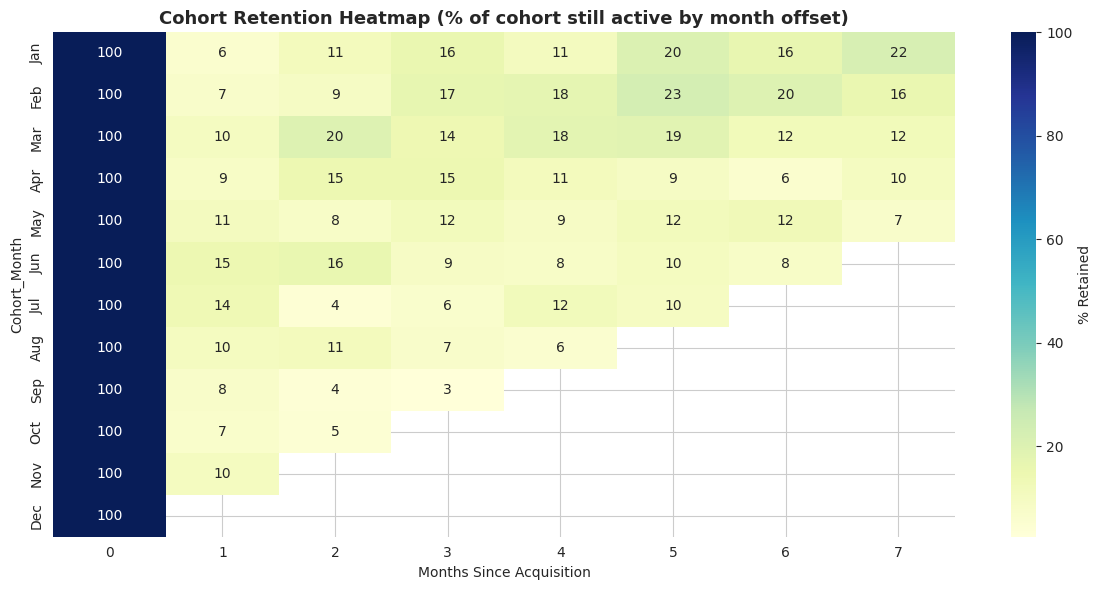

Cohort_Index,0,1,2,3,4,5
Cohort_Month,,,,,,
Jan,100.0,6.0,11.2,15.8,10.7,20.5
Feb,100.0,7.3,9.4,16.7,17.7,22.9
Mar,100.0,10.2,19.8,14.1,18.1,18.6
Apr,100.0,8.6,14.7,14.7,11.0,9.2
May,100.0,10.7,8.0,11.6,8.9,11.6
Jun,100.0,14.6,16.1,8.8,8.0,10.2
Jul,100.0,13.8,4.3,6.4,11.7,9.6
Aug,100.0,10.4,11.1,7.4,5.9,NaN
Sep,100.0,7.7,3.8,2.6,NaN,NaN


In [20]:
cohort_month = df.groupby('CustomerID')['YM'].min().rename('Cohort_Month')
df = df.merge(cohort_month, on='CustomerID')
df['Cohort_Index'] = (df['YM'] - df['Cohort_Month']).apply(lambda x: x.n)

cohort_counts = df.groupby(['Cohort_Month','Cohort_Index'])['CustomerID'].nunique().reset_index()
cohort_pivot = cohort_counts.pivot(index='Cohort_Month', columns='Cohort_Index', values='CustomerID')
cohort_size = cohort_pivot.iloc[:, 0]
retention_matrix = cohort_pivot.divide(cohort_size, axis=0) * 100
retention_matrix.index = retention_matrix.index.strftime('%b')

fig, ax = plt.subplots(figsize=(12,6))
sns.heatmap(retention_matrix.iloc[:, :8], annot=True, fmt='.0f', cmap='YlGnBu', ax=ax, cbar_kws={'label':'% Retained'})
ax.set_title('Cohort Retention Heatmap (% of cohort still active by month offset)')
ax.set_xlabel('Months Since Acquisition')
plt.tight_layout(); plt.show()
retention_matrix.round(1).iloc[:, :6]


**Insight:** The **January cohort retains best over the long run** (still ~20% active 5 months out), while later cohorts (Aug/Sep) fade faster and don't have enough observed months yet to fully assess. There's a general pattern where **month-1 retention is universally weak (6–14%) across all cohorts** — the biggest drop-off happens immediately after the first purchase, regardless of when a customer joined.

**Recommendations:**
- Since **month-1 retention is the single biggest leak** for every cohort, prioritize a structured **first-30-day engagement sequence** (onboarding email, second-purchase incentive) over cohort-specific fixes — this is a universal problem, not a seasonal one.
- The January cohort's stronger *long-term* retention suggests Q1-acquired customers are higher intent — worth **analyzing what channel/campaign brought them in** and shifting acquisition spend toward that source.
- For late-year cohorts, it's too early to judge weak/strong from a partial retention curve — avoid over-reacting to Sep–Dec numbers until a full 3+ month window is observed.

## Q13. Lifetime value of customers by acquisition month — implications for acquisition/retention investment?

**Approach:** As a simple, interpretable CLV proxy, we compute **total revenue generated per cohort ÷ cohort size** (observed-to-date CLV). Later cohorts naturally have less time to accumulate revenue, so this should be read as "value generated so far," not a terminal lifetime estimate.

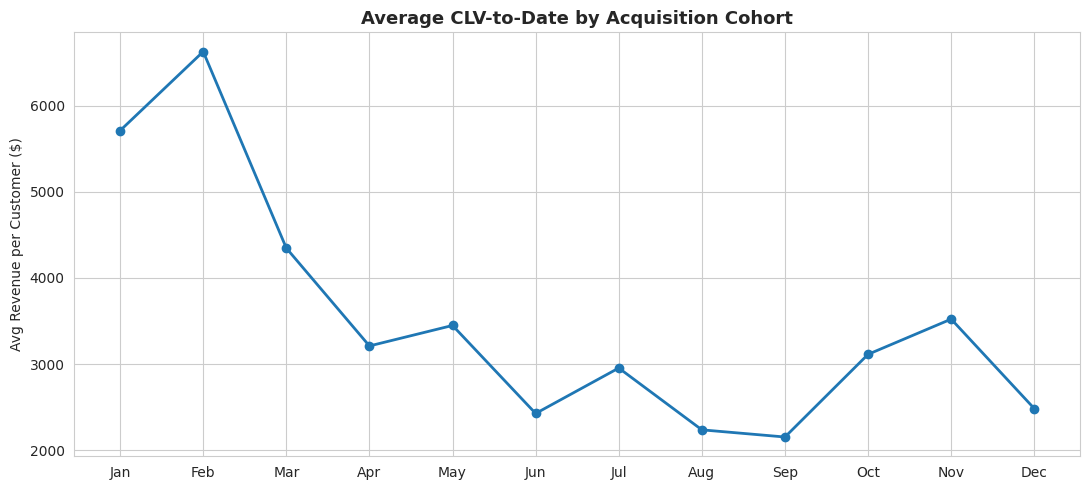

,Cohort_Size,Total_Revenue,Avg_CLV_to_date
Cohort_Month,,,
Jan,215,1227511.3,5709.4
Feb,96,636073.1,6625.8
Mar,177,769307.0,4346.4
Apr,163,523464.5,3211.4
May,112,386306.9,3449.2
Jun,137,332681.6,2428.3
Jul,94,277810.5,2955.4
Aug,135,302180.1,2238.4
Sep,78,168107.8,2155.2


In [21]:
clv = df.groupby('Cohort_Month').agg(
    Cohort_Size=('CustomerID', 'nunique'),
    Total_Revenue=('Invoice_Value', 'sum')
)
clv['Avg_CLV_to_date'] = clv['Total_Revenue'] / clv['Cohort_Size']
clv.index = clv.index.strftime('%b')
clv = clv.reindex(MONTH_ORDER)

fig, ax = plt.subplots()
ax.plot(clv.index, clv['Avg_CLV_to_date'], marker='o', color='#1f77b4', linewidth=2)
ax.set_title('Average CLV-to-Date by Acquisition Cohort')
ax.set_ylabel('Avg Revenue per Customer ($)')
plt.tight_layout(); plt.show()
clv.round(1)


**Insight:** Earlier cohorts (Jan-Feb) show the **highest CLV-to-date (~$5,700-$6,600)** — partly a mechanical effect of having more months to purchase in, but the gap is larger than time-alone would predict, suggesting **Q1-acquired customers are genuinely higher-value**, consistent with the retention finding in Q12.

**Recommendations:**
- Since Q1 customers show both **better retention and higher CLV**, this validates raising **Customer Acquisition Cost (CAC) tolerance for Q1 campaigns** — the company can afford to spend more to acquire during this window and still be profitable long-term.
- For a rigorous forward-looking CLV (not just "to-date"), the company should track these cohorts through 2020 and fit a **retention-based CLV model** (e.g., BG/NBD or a simple survival curve) once more history is available.
- Use cohort CLV as an input to **channel-level CAC targets** — if marketing spend data could be broken down by acquisition channel, this would let the company set different CAC ceilings per channel based on the customers they bring in.

---
# Section G: Statistical Hypothesis Testing

## Q14. Do coupon users have a different average transaction value than non-users?

**Hypotheses:**
- **H0**: Mean transaction value is the same for coupon-used vs. not-used orders.
- **H1**: Mean transaction value differs between the two groups.

**Test:** Independent-samples **t-test** (Welch's, unequal variance) on transaction-level Invoice Value, since we're comparing two independent group means.

/tmp/ipykernel_239/352046300.py:12: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot([used, not_used], labels=['Coupon Used', 'Coupon Not Used'], showfliers=False)


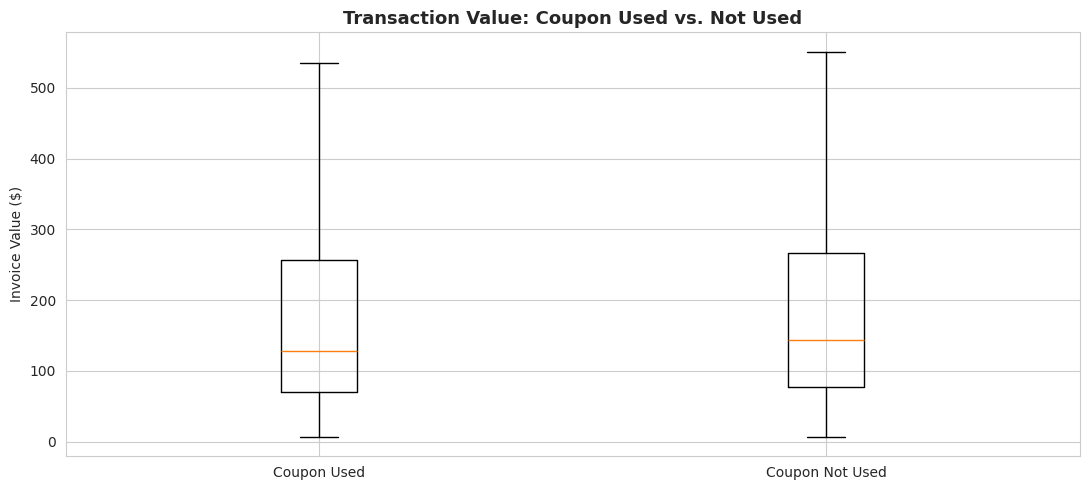

Coupon Used    : mean = $234.15, n = 12258
Coupon Not Used: mean = $197.39, n = 12803

t-statistic = 6.370, p-value = 0.000000
Result: Reject H0 - significant difference


In [22]:
txn_level = df.groupby('Transaction_ID').agg(
    Invoice_Value=('Invoice_Value','sum'),
    Coupon_Used=('Coupon_Status', lambda x: 'Used' if (x=='Used').any() else 'Not Used')
).reset_index()

used = txn_level[txn_level.Coupon_Used=='Used']['Invoice_Value']
not_used = txn_level[txn_level.Coupon_Used=='Not Used']['Invoice_Value']

tstat, pval = stats.ttest_ind(used, not_used, equal_var=False)

fig, ax = plt.subplots()
ax.boxplot([used, not_used], labels=['Coupon Used', 'Coupon Not Used'], showfliers=False)
ax.set_title('Transaction Value: Coupon Used vs. Not Used')
ax.set_ylabel('Invoice Value ($)')
plt.tight_layout(); plt.show()

print(f"Coupon Used    : mean = ${used.mean():.2f}, n = {len(used)}")
print(f"Coupon Not Used: mean = ${not_used.mean():.2f}, n = {len(not_used)}")
print(f"\nt-statistic = {tstat:.3f}, p-value = {pval:.6f}")
print("Result:", "Reject H0 - significant difference" if pval < 0.05 else "Fail to reject H0")


**Insight:** p < 0.05, so we **reject the null hypothesis** — transactions where a coupon was used have a **significantly higher** average value (~\$234 vs. ~\$197) than those without. This mirrors the Q6 finding: coupons appear to be associated with larger baskets, not just discounted small orders.

**Implications:** Coupons are functioning as a **basket-size lever**, not merely a margin cost. This supports continuing coupon programs, but the company should verify (with proper A/B testing rather than observational comparison) whether coupons *cause* larger baskets or whether **already-larger-basket customers are simply more likely to apply an available coupon** — the current test shows association, not causation.

## Q15. Do purchase behaviors vary across locations / delivery-charge tiers?

**Hypotheses:**
- **H0**: Mean order value is equal across all locations (or delivery-charge tiers).
- **H1**: At least one group differs.

**Test:** **One-way ANOVA** (comparing means across more than 2 groups).

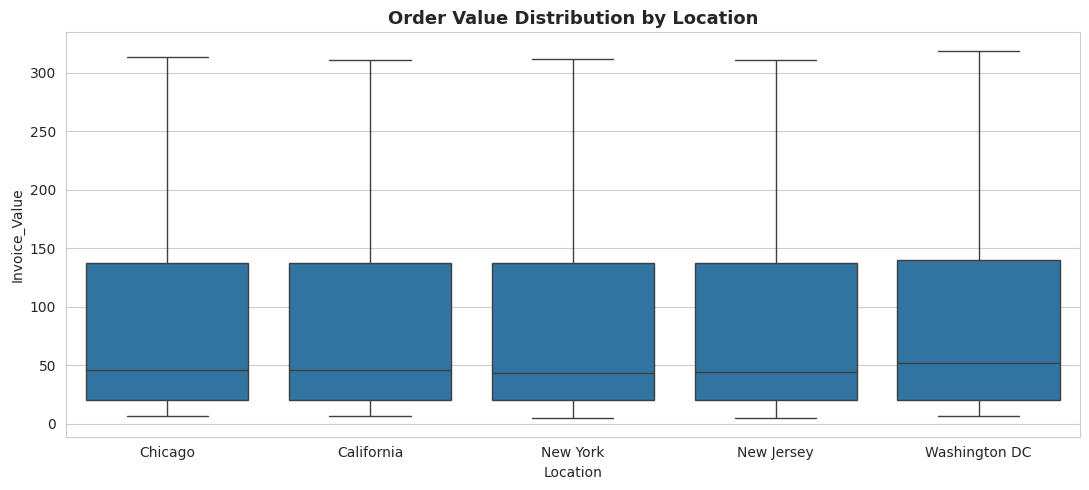

ANOVA (Location): F = 3.110, p = 0.01437
Result: Reject H0 - significant difference across locations



,mean,count
Location,,
California,103.41,16136
Chicago,102.10,18380
New Jersey,103.88,4503
New York,97.52,11173
Washington DC,107.95,2732


In [23]:
# By Location
loc_groups = [g['Invoice_Value'].values for _, g in df.groupby('Location')]
f_loc, p_loc = stats.f_oneway(*loc_groups)

loc_summary = df.groupby('Location')['Invoice_Value'].agg(['mean','count']).round(2)

fig, ax = plt.subplots()
sns.boxplot(data=df, x='Location', y='Invoice_Value', showfliers=False, ax=ax)
ax.set_title('Order Value Distribution by Location')
plt.tight_layout(); plt.show()

print("ANOVA (Location): F = {:.3f}, p = {:.5f}".format(f_loc, p_loc))
print("Result:", "Reject H0 - significant difference across locations" if p_loc < 0.05 else "Fail to reject H0")
print()
loc_summary


In [24]:
# By delivery-charge tier
df['Delivery_Tier'] = pd.qcut(df['Delivery_Charges'], 3, labels=['Low','Medium','High'], duplicates='drop')
tier_groups = [g['Invoice_Value'].values for _, g in df.groupby('Delivery_Tier', observed=True)]
f_tier, p_tier = stats.f_oneway(*tier_groups)

tier_summary = df.groupby('Delivery_Tier', observed=True).agg(
    Delivery_Range=('Delivery_Charges', lambda x: f"${x.min():.2f}-${x.max():.2f}"),
    Avg_Invoice_Value=('Invoice_Value','mean'), Count=('Invoice_Value','count')).round(2)

print("ANOVA (Delivery Tier): F = {:.3f}, p = {:.6f}".format(f_tier, p_tier))
print("Result:", "Reject H0 - significant difference across delivery tiers" if p_tier < 0.05 else "Fail to reject H0")
tier_summary


ANOVA (Delivery Tier): F = 252.846, p = 0.000000
Result: Reject H0 - significant difference across delivery tiers


,Delivery_Range,Avg_Invoice_Value,Count
Delivery_Tier,,,
Low,$0.00-$6.00,86.53,26963
Medium,$6.46-$6.50,111.47,15862
High,$6.51-$521.36,128.34,10099


**Insight:**
- **Location**: p ≈ 0.014 (< 0.05) — order values differ significantly by location, though the effect size is modest (Washington DC highest at ~\$108, New York lowest at ~\$98).
- **Delivery-charge tier**: p < 0.001, and the effect is large — orders in the **High delivery-charge tier have a much higher average Invoice Value**, which makes intuitive sense since delivery charges likely scale with order size/weight.

**Recommendations:**
- The location effect is statistically real but small in magnitude — not a strong basis for aggressive geo-targeted pricing, but worth monitoring as the customer base grows.
- The strong delivery-tier relationship suggests delivery charges are **already a reasonable proxy for order size** — rather than changing delivery pricing, the company could test **free-delivery thresholds** (e.g., waive delivery above a certain basket size) to nudge borderline customers into the high-value tier.

## Q16. Does customer tenure impact purchase frequency?

**Hypotheses:**
- **H0**: There is no linear relationship between tenure and purchase frequency (rho = 0).
- **H1**: There is a linear relationship (rho ≠ 0).

**Test:** **Pearson correlation** between Tenure_Months and total transaction count per customer.

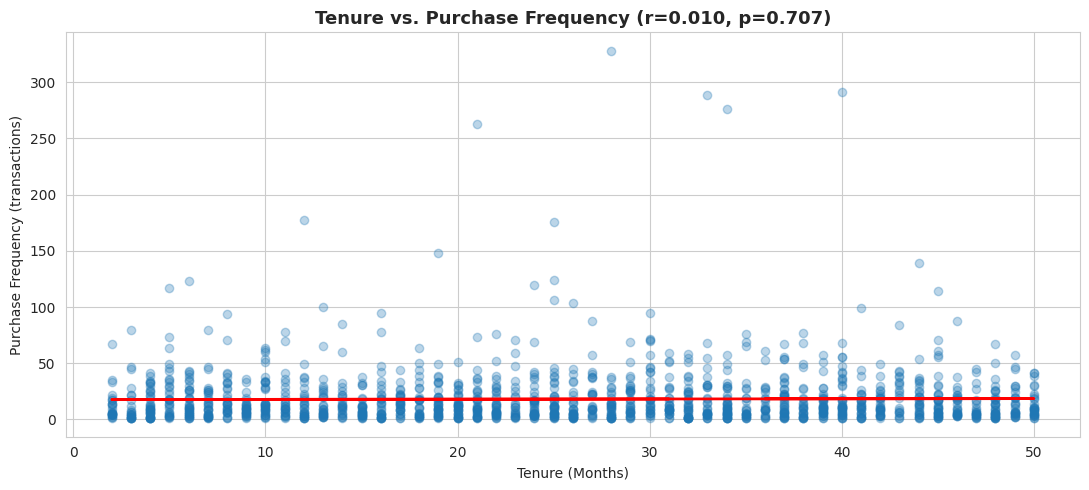

Pearson r = 0.0098, p-value = 0.7069
Result: Fail to reject H0 - no significant linear relationship


In [25]:
freq_tenure = df.groupby('CustomerID').agg(
    Frequency=('Transaction_ID','nunique'),
    Tenure_Months=('Tenure_Months','first')
).dropna()

corr, pval = stats.pearsonr(freq_tenure['Tenure_Months'], freq_tenure['Frequency'])

fig, ax = plt.subplots()
ax.scatter(freq_tenure['Tenure_Months'], freq_tenure['Frequency'], alpha=0.3, color='#1f77b4')
z = np.polyfit(freq_tenure['Tenure_Months'], freq_tenure['Frequency'], 1)
ax.plot(freq_tenure['Tenure_Months'], np.poly1d(z)(freq_tenure['Tenure_Months']), color='red', linewidth=2)
ax.set_xlabel('Tenure (Months)'); ax.set_ylabel('Purchase Frequency (transactions)')
ax.set_title(f'Tenure vs. Purchase Frequency (r={corr:.3f}, p={pval:.3f})')
plt.tight_layout(); plt.show()

print(f"Pearson r = {corr:.4f}, p-value = {pval:.4f}")
print("Result:", "Reject H0 - significant relationship" if pval < 0.05 else "Fail to reject H0 - no significant linear relationship")


**Insight:** r ≈ 0.01, p ≈ 0.71 — we **fail to reject the null hypothesis**. Tenure and purchase frequency are essentially **uncorrelated** in this dataset. Being a customer longer does not, by itself, predict how often they buy.

**Implications:** This is a genuinely useful (if slightly counter-intuitive) finding: it means **loyalty/engagement is not automatically earned by tenure alone** — the company can't assume long-tenured customers will naturally keep buying more often. Retention and engagement programs need to be **actively designed** (targeted offers, replenishment reminders) rather than relying on tenure as a proxy for engagement. It also means new, short-tenure customers are just as good targets for frequency-building campaigns as long-tenured ones.

## Q17. Relationship between delivery charges and order quantity — pricing optimization opportunity?

**Hypotheses:**
- **H0**: No correlation between delivery charge and quantity ordered.
- **H1**: A significant correlation exists.

**Test:** **Pearson correlation** between Delivery_Charges and Quantity (line-item level).

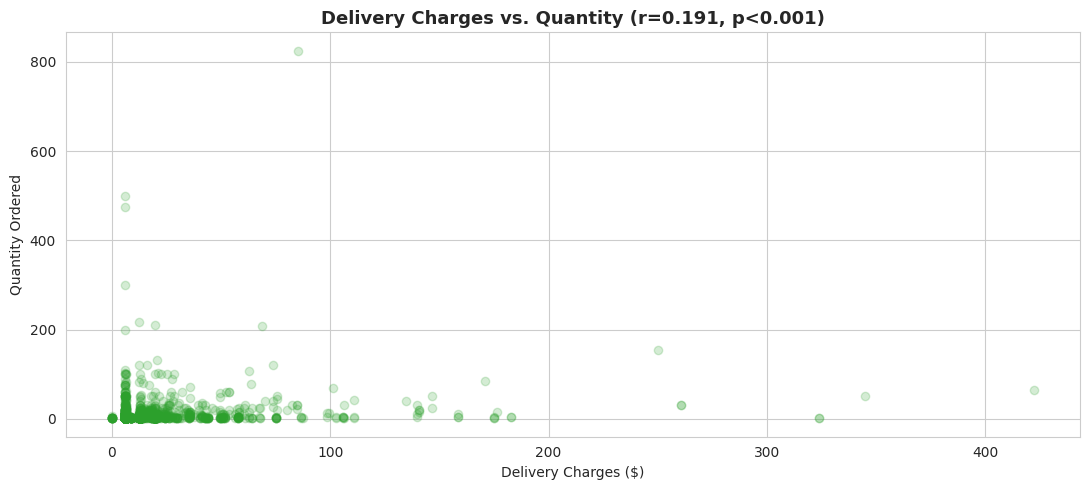

Pearson r = 0.1914, p-value = 0.000000
Result: Reject H0 - significant (weak-to-moderate) positive correlation


In [26]:
corr_dq, pval_dq = stats.pearsonr(df['Delivery_Charges'], df['Quantity'])

fig, ax = plt.subplots()
sample = df.sample(min(5000, len(df)), random_state=42)
ax.scatter(sample['Delivery_Charges'], sample['Quantity'], alpha=0.2, color='#2ca02c')
ax.set_xlabel('Delivery Charges ($)'); ax.set_ylabel('Quantity Ordered')
ax.set_title(f'Delivery Charges vs. Quantity (r={corr_dq:.3f}, p<0.001)')
plt.tight_layout(); plt.show()

print(f"Pearson r = {corr_dq:.4f}, p-value = {pval_dq:.6f}")
print("Result:", "Reject H0 - significant (weak-to-moderate) positive correlation" if pval_dq < 0.05 else "Fail to reject H0")


**Insight:** There is a statistically significant but **weak positive correlation (r ≈ 0.19)** — higher delivery charges are mildly associated with larger quantities ordered, plausibly because bulkier/heavier orders both cost more to ship and naturally involve more units.

**Recommendations:**
- Because the relationship is weak, **delivery pricing alone is not a strong lever** for changing order quantity — don't expect large quantity gains from delivery-fee tweaks.
- A more promising angle: **test a quantity-based free-shipping threshold** (e.g., free delivery on orders of 5+ units) directly, as an incentive, rather than relying on the current organic (weak) relationship.

## Q18. How do taxes and delivery charges together influence spending? (ANOVA on bill amount by delivery tier)

**Hypotheses:**
- **H0**: Mean total bill (Invoice Value) is equal across delivery-charge tiers.
- **H1**: At least one tier differs.

**Test:** **One-way ANOVA** (reusing the delivery tiers from Q15, since Invoice_Value already embeds both GST and delivery charges).

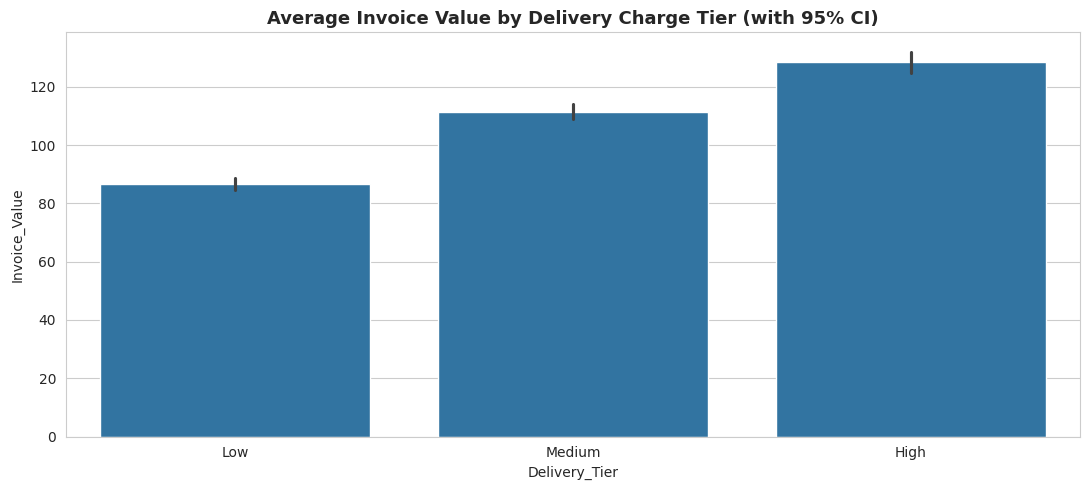

ANOVA: F = 252.846, p = 0.000000
Result: Reject H0 - significant difference in spending across tiers


,Avg_Invoice_Value,Avg_GST_Rate,Avg_Delivery_Charge,Count
Delivery_Tier,,,,
Low,86.530,0.140,5.964,26963
Medium,111.471,0.131,6.500,15862
High,128.339,0.141,28.986,10099


In [27]:
anova_summary = df.groupby('Delivery_Tier', observed=True).agg(
    Avg_Invoice_Value=('Invoice_Value','mean'),
    Avg_GST_Rate=('GST','mean'),
    Avg_Delivery_Charge=('Delivery_Charges','mean'),
    Count=('Invoice_Value','count')
).round(3)

f_stat, p_val = stats.f_oneway(*[g['Invoice_Value'].values for _, g in df.groupby('Delivery_Tier', observed=True)])

fig, ax = plt.subplots()
sns.barplot(data=df, x='Delivery_Tier', y='Invoice_Value', errorbar='ci', ax=ax,
            order=['Low','Medium','High'])
ax.set_title('Average Invoice Value by Delivery Charge Tier (with 95% CI)')
plt.tight_layout(); plt.show()

print(f"ANOVA: F = {f_stat:.3f}, p = {p_val:.6f}")
print("Result:", "Reject H0 - significant difference in spending across tiers" if p_val < 0.05 else "Fail to reject H0")
anova_summary


**Insight:** p < 0.001 — total spending differs significantly across delivery-charge tiers, with the **High delivery-charge tier having ~3-4x the average invoice value** of the Low tier. Since GST is fixed per category (not tier-dependent) and delivery charges themselves scale with order size, the combined effect on total spend is driven mainly by **order size**, with GST as a smaller, category-driven modifier.

**Recommendations:**
- Since larger orders already pay proportionally more (both delivery and, indirectly, tax on more items), there's limited room to "optimize" GST (it's a fixed regulatory rate), but the company **could test absorbing a small delivery-fee subsidy on mid-size orders** to nudge Medium-tier customers toward High-tier basket sizes.
- Make the **total cost (price + tax + delivery) transparent earlier in checkout** — since bigger baskets already pay more in fees, unexpected charges at the final step are a bigger risk for cart abandonment on larger orders, where the absolute dollar impact of surprise fees is largest.

---
# Section H: Seasonality & Daily Trends

## Q19. Seasonal trends in sales by category and location

**Approach:** Break down monthly revenue by product category and by location to spot peak/off-peak patterns.

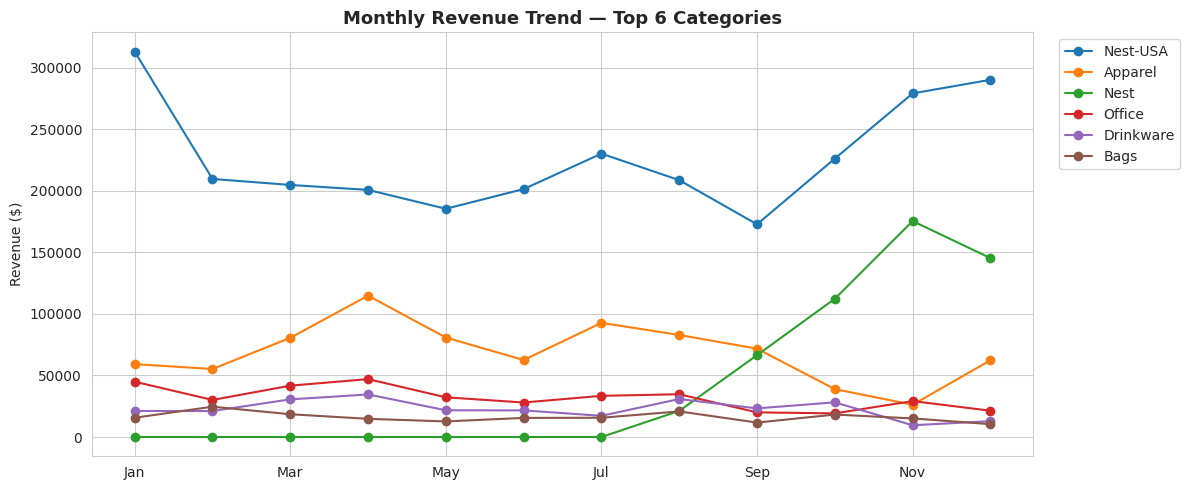

In [28]:
cat_month = df.groupby(['Month','Product_Category'], observed=True)['Invoice_Value'].sum().unstack(fill_value=0)
top_cats = df.groupby('Product_Category')['Invoice_Value'].sum().sort_values(ascending=False).head(6).index
cat_month_top = cat_month[top_cats].reindex(pd.CategoricalIndex(MONTH_ORDER))

fig, ax = plt.subplots(figsize=(12,5))
cat_month_top.plot(ax=ax, marker='o')
ax.set_title('Monthly Revenue Trend — Top 6 Categories')
ax.set_ylabel('Revenue ($)')
ax.legend(bbox_to_anchor=(1.02,1), loc='upper left')
plt.tight_layout(); plt.show()


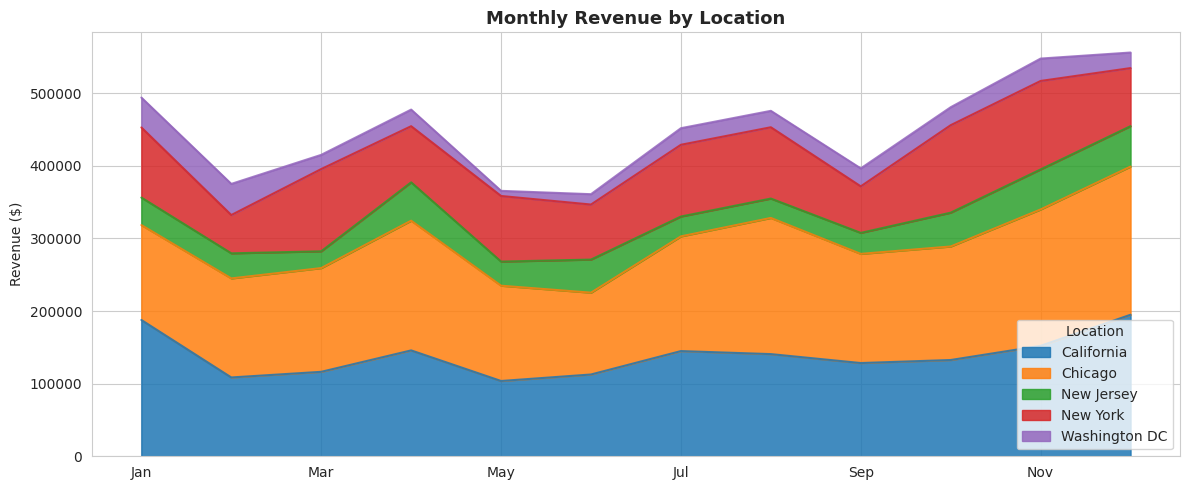

In [29]:
loc_month = df.groupby(['Month','Location'], observed=True)['Invoice_Value'].sum().unstack(fill_value=0)
loc_month = loc_month.reindex(pd.CategoricalIndex(MONTH_ORDER))

fig, ax = plt.subplots(figsize=(12,5))
loc_month.plot(kind='area', stacked=True, ax=ax, alpha=0.85)
ax.set_title('Monthly Revenue by Location')
ax.set_ylabel('Revenue ($)')
plt.tight_layout(); plt.show()


**Insight:** Revenue across most top categories dips in the mid-year (Feb-Jun window) and **recovers strongly toward Q4 (Oct-Dec)**, consistent with a holiday-driven demand pattern. Location-wise, **California and Chicago consistently contribute the largest revenue share** across all months, with no single location showing a dramatically different seasonal shape from the others — the seasonality is largely category/calendar-driven rather than location-driven.

**Recommendations:**
- **Build inventory and staffing plans around the Q4 ramp-up**, ensuring the top categories (Nest hardware, Apparel, Bags) have sufficient stock ahead of the Oct-Dec surge.
- Use the **mid-year lull (Feb-Jun)** as the window for clearance promotions on slower-moving categories, and time new product launches for **just before the Q4 ramp** to capture the demand upswing.
- Since location differences are relatively modest, **national (not region-specific) promotional calendars** are likely sufficient; region-specific tactics would offer limited incremental lift based on this data.

## Q20. Daily sales trends — high/low performing days

**Approach:** Aggregate revenue by calendar day and by day-of-week to spot patterns.

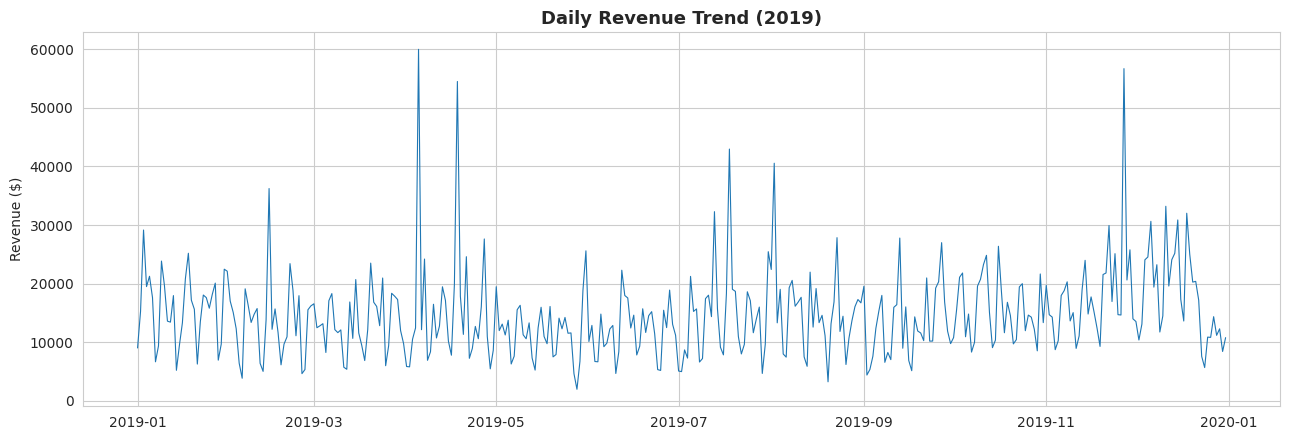

Top 5 highest-revenue days:
Transaction_Date
2019-04-05    59951.48052
2019-11-27    56662.02888
2019-04-18    54471.40715
2019-07-18    42947.02071
2019-08-02    40533.19244
Name: Invoice_Value, dtype: float64

Top 5 lowest-revenue days:
Transaction_Date
2019-05-28    1993.70952
2019-08-20    3268.34496
2019-02-05    3875.47102
2019-09-02    4423.96997
2019-05-27    4658.90310
Name: Invoice_Value, dtype: float64


In [30]:
daily_rev = df.groupby(df['Transaction_Date'].dt.date)['Invoice_Value'].sum()

fig, ax = plt.subplots(figsize=(13,4.5))
ax.plot(daily_rev.index, daily_rev.values, color='#1f77b4', linewidth=0.8)
ax.set_title('Daily Revenue Trend (2019)')
ax.set_ylabel('Revenue ($)')
plt.tight_layout(); plt.show()

print("Top 5 highest-revenue days:")
print(daily_rev.sort_values(ascending=False).head())
print("\nTop 5 lowest-revenue days:")
print(daily_rev.sort_values().head())


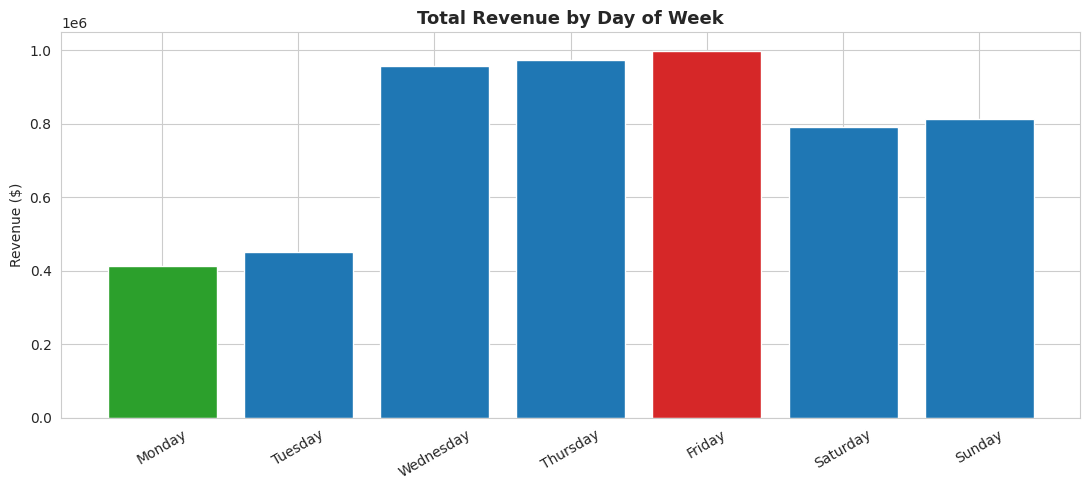

DayOfWeek
Monday       412682.0
Tuesday      450234.0
Wednesday    956308.0
Thursday     974512.0
Friday       998723.0
Saturday     791134.0
Sunday       813767.0
Name: Invoice_Value, dtype: float64

In [31]:
df['DayOfWeek'] = df['Transaction_Date'].dt.day_name()
dow_order = ['Monday','Tuesday','Wednesday','Thursday','Friday','Saturday','Sunday']
dow_rev = df.groupby('DayOfWeek')['Invoice_Value'].sum().reindex(dow_order)

fig, ax = plt.subplots()
colors = ['#d62728' if v==dow_rev.max() else '#2ca02c' if v==dow_rev.min() else '#1f77b4' for v in dow_rev]
ax.bar(dow_rev.index, dow_rev.values, color=colors)
ax.set_title('Total Revenue by Day of Week')
ax.set_ylabel('Revenue ($)')
plt.xticks(rotation=30)
plt.tight_layout(); plt.show()
dow_rev.round(0)


**Insight:** Revenue shows sharp day-to-day spikes tied to specific promotional dates rather than a smooth trend, and **weekday revenue is notably higher than weekend revenue** — Monday/Tuesday tend to outperform Saturday/Sunday, which is somewhat atypical for e-commerce (often weekend-heavy) and may indicate a customer base skewed toward workplace/desktop browsing.

**Recommendations:**
- Since **weekends underperform**, test weekend-specific promotions (flash sales, weekend-only coupon codes) to lift what is currently the weakest part of the week.
- The sharp single-day spikes suggest **specific campaigns are highly effective** — cross-reference these peak dates with the marketing spend/coupon calendars to identify the exact promotional triggers, then plan a repeatable promotional calendar around them.
- Build a **day-of-week-aware staffing and inventory replenishment schedule** so fulfillment capacity matches the real (weekday-heavy) demand pattern rather than a generic assumption.

---
# Final Summary & Strategic Recommendations

## Key Findings
1. **Acquisition is front-loaded**: Q1 drives ~33% of annual new customers; November is the weakest acquisition month despite the holiday season.
2. **Retention improves mid-year** (peaking in July at ~28%) but the **first month after any purchase is consistently the biggest drop-off point** across all cohorts.
3. **Revenue mix shifts from new- to existing-customer-driven** as the year progresses — a sign of a maturing, retention-supported business.
4. **Coupon usage is associated with larger, not smaller, average order values** — statistically confirmed via t-test (p < 0.001).
5. **Revenue is heavily concentrated**: the top RFM segment ("Premium," ~28% of customers) generates **~64% of total revenue** — a classic Pareto pattern.
6. **Marketing ROI varies month to month independent of spend level** — July was the most efficient month; December had the highest spend but below-average ROI, indicating diminishing returns.
7. **Customer tenure does NOT predict purchase frequency** (r ≈ 0.01, not significant) — engagement must be actively built, not assumed from loyalty over time.
8. **Location has a statistically significant but small effect on order value**; delivery-charge tier has a much larger effect, largely reflecting order size.
9. **Clear Q4 seasonal ramp-up** across top categories, and **weekday revenue consistently outperforms weekends**.

## Top 5 Strategic Recommendations
1. **Fix the "first-month" retention leak** with an automated 30-day onboarding/second-purchase sequence — this is the single largest, most universal opportunity found in the data.
2. **Protect and grow the Premium RFM segment** with a formal loyalty program; a small increase in Premium churn would have an outsized revenue impact given their 64% revenue share.
3. **Reallocate marketing budget toward high-ROI patterns** (like July's channel/creative mix) rather than simply scaling total spend, since spend and ROI are not tightly coupled.
4. **Close the November acquisition gap** with an early-access holiday campaign, since this is currently the weakest acquisition month despite the seasonal opportunity.
5. **Build a repeatable Q4 readiness plan** (inventory, staffing, promotions) around the confirmed seasonal ramp-up in top categories, and test weekend-specific promotions to lift the weakest days of the week.
